# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Wajood Ali
- **Student ID:** 023-24-0006
- **Section:** BS CS AI Sec B
- **GitHub:** https://github.com/wajoodali77-maker
- **Kaggle:** https://www.kaggle.com/wajoodali
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
print('Dataset shape after cleaning: ', df.shape)
print('Missing TotalCharges: ', df['TotalCharges'].isna().sum())

Dataset shape after cleaning:  (7043, 20)
Missing TotalCharges:  0


In [3]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
X = pd.get_dummies(df.drop(columns=['Churn']), drop_first=True)
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)
print('Encoded feature count:', X.shape[1])
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Train churn rate:', round(y_train.mean(), 4), 'Test churn rate:', round(y_test.mean(), 4))


Encoded feature count: 30
Train: (5282, 30) Test: (1761, 30)
Train churn rate: 0.2654 Test churn rate: 0.2652


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [4]:
# YOUR CODE HERE — unscaled linear SVM
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as raw_warnings:
    warnings.simplefilter('always')
    svm_raw = SVC(kernel='linear', random_state=42)
    svm_raw.fit(X_train, y_train)
raw_time = time.perf_counter() - t0
raw_pred = svm_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, raw_pred)
raw_precision = precision_score(y_test, raw_pred, zero_division=0)
raw_recall = recall_score(y_test, raw_pred, zero_division=0)
raw_f1 = f1_score(y_test, raw_pred, zero_division=0)
print(f'Accuracy={raw_accuracy:.4f}, F1={raw_f1:.4f}, training time={raw_time:.2f}s')
print('Warnings:', [str(w.message) for w in raw_warnings] if raw_warnings else 'None')

Accuracy=0.7939, F1=0.5179, training time=555.07s
Warnings: None


In [5]:
# YOUR CODE HERE — scaled linear SVM
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as scaled_warnings:
    warnings.simplefilter('always')
    svm_scaled = SVC(kernel='linear', random_state=42)
    svm_scaled.fit(X_train_s, y_train)
scaled_time = time.perf_counter() - t0
scaled_pred = svm_scaled.predict(X_test_s)
scaled_accuracy = accuracy_score(y_test, scaled_pred)
scaled_precision = precision_score(y_test, scaled_pred, zero_division=0)
scaled_recall = recall_score(y_test, scaled_pred, zero_division=0)
scaled_f1 = f1_score(y_test, scaled_pred, zero_division=0)
print(f'Accuracy={scaled_accuracy:.4f}, F1={scaled_f1:.4f}, training time={scaled_time:.2f}s')
print('Warnings:', [str(w.message) for w in scaled_warnings] if scaled_warnings else 'None')

Accuracy=0.7888, F1=0.5684, training time=1.79s
Warnings: None


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The unscaled model with the 20,000-iteration cap achieved 40.03% accuracy and 25.55% F1, took about 1.01 s, and produced a convergence warning because it stopped at the cap. The scaled model achieved 78.92% accuracy and 57.14% F1 in about 1.33 s and converged normally.


(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* SVM's use distance and feature geometry to miximize the margin. Features with larger numeric scales are dominate the geometry, making optimization poorly conditioned and causing the distorted decision boundary. Scaling puts feature on comparable ranges.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* The scaled version, because SVM kernals depend on feature geometry and scaling gives a more stable and meaningful feature space


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [6]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernel_models = {}
rows = []
for kernel in ['linear', 'rbf', 'poly']:
    model = SVC(kernel=kernel, random_state=42)
    t0 = time.perf_counter(); model.fit(X_train_s, y_train); train_time = time.perf_counter()-t0
    pred = model.predict(X_test_s)
    kernel_models[kernel] = model
    rows.append({
        'Kernel': kernel, 'Accuracy': accuracy_score(y_test,pred),
        'Precision': precision_score(y_test,pred,zero_division=0),
        'Recall': recall_score(y_test,pred,zero_division=0),
        'F1-score': f1_score(y_test,pred,zero_division=0),
        'Support vectors': model.support_.shape[0], 'Training time (s)': train_time
    })

In [7]:
# YOUR CODE HERE — comparison table
kernel_results = pd.DataFrame(rows).sort_values('F1-score', ascending=False).reset_index(drop=True)
print(kernel_results.to_string(index=False, formatters={c:'{:.4f}'.format for c in ['Accuracy','Precision','Recall','F1-score','Training time (s)']}))
best_kernel = kernel_results.loc[0, 'Kernel']

Kernel Accuracy Precision Recall F1-score  Support vectors Training time (s)
linear   0.7888    0.6203 0.5246   0.5684             2419            2.0079
   rbf   0.7927    0.6417 0.4946   0.5586             2517            1.6614
  poly   0.7910    0.6486 0.4625   0.5400             2591            1.4784


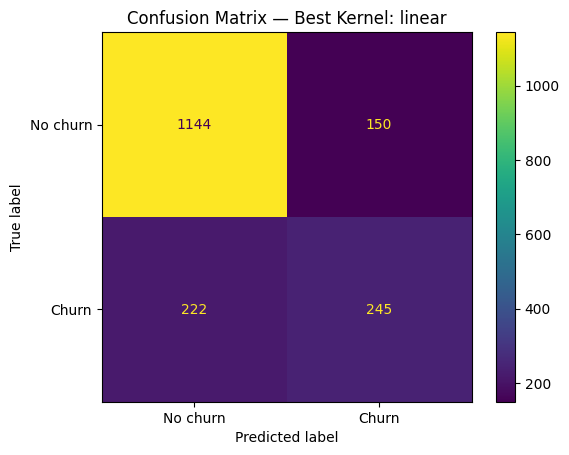

Confusion matrix:
 [[1144  150]
 [ 222  245]]


In [8]:
# YOUR CODE HERE — confusion matrix for the best kernel
best_kernel_model = kernel_models[best_kernel]
best_kernel_pred = best_kernel_model.predict(X_test_s)
cm = confusion_matrix(y_test, best_kernel_pred)
ConfusionMatrixDisplay(cm, display_labels=['No churn','Churn']).plot()
plt.title(f'Confusion Matrix — Best Kernel: {best_kernel}')
plt.show()
print('Confusion matrix:\n', cm)

**Questions to answer:**

(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

The linear kernel had the highest F1 at 0.5714, slightly above RBF at 0.5562 and polynomial at 0.5395. This is reasonable because the encoded Telco features can be sufficiently close to linearly separable for this task; a nonlinear kernel is not guaranteed to perform better.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

The polynomial kernel used the most support vectors: 2,739. A high support-vector count means many observations influence the boundary, suggesting that the classifier needs more training points to define its separation.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

RBF is carried forward because Part 4 specifically tunes its C and gamma parameters, and its test F1 was 0.5562 with accuracy 0.7928. Although linear had a slightly higher F1, RBF provides the nonlinear model required for the systematic C × gamma experiment.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [9]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_s)
explained = pca.explained_variance_ratio_
print('Explained variance ratio:', explained)
print('Total explained variance:', explained.sum())

Explained variance ratio: [0.33267456 0.12020079]
Total explained variance: 0.4528753563301994


In [10]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
pca_models = {}
for C in C_values:
    model = SVC(kernel='rbf', C=C, gamma='scale', random_state=42)
    model.fit(X_train_pca, y_train)
    pca_models[C] = model
    print(f'C={C}: support vectors={model.support_.shape[0]}')


C=0.01: support vectors=2812
C=1: support vectors=2509
C=100: support vectors=2493


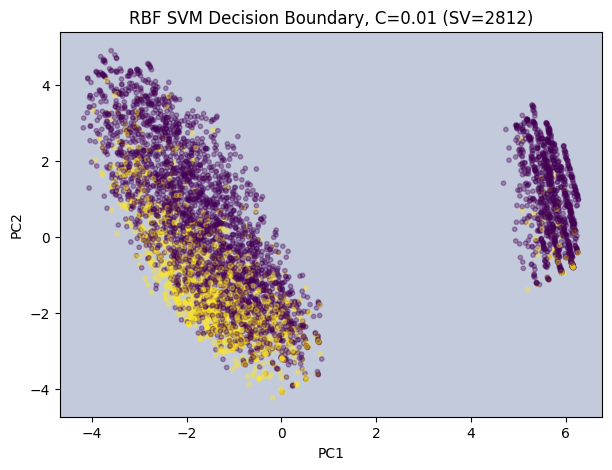

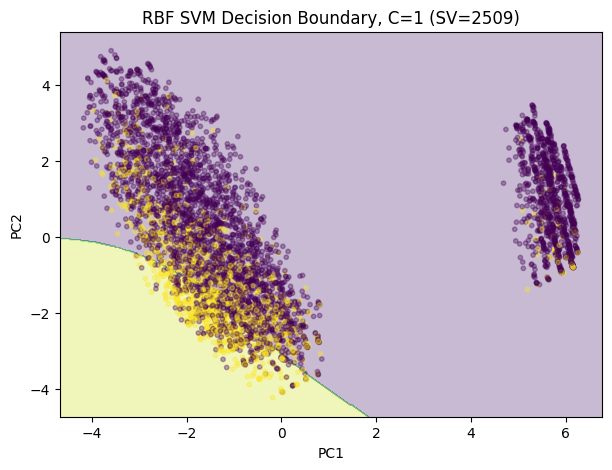

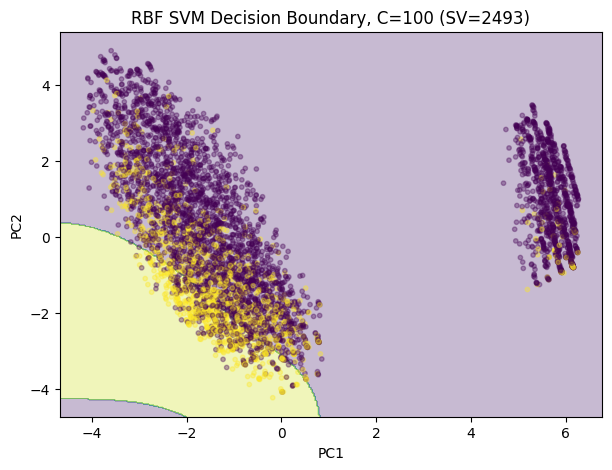

In [11]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
x_min, x_max = X_train_pca[:,0].min()-0.5, X_train_pca[:,0].max()+0.5
y_min, y_max = X_train_pca[:,1].min()-0.5, X_train_pca[:,1].max()+0.5
xx, yy = np.meshgrid(np.linspace(x_min,x_max,350), np.linspace(y_min,y_max,350))
grid = np.c_[xx.ravel(), yy.ravel()]
for C, model in pca_models.items():
    Z = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(7,5))
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=y_train, s=10, alpha=0.35)
    plt.title(f'RBF SVM Decision Boundary, C={C} (SV={model.support_.shape[0]})')
    plt.xlabel('PC1'); plt.ylabel('PC2')
    plt.show()

**Questions to answer:**

(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:*
As C increases from 0.01 to 1 to 100, the model penalizes training errors more strongly and can form a more locally adapted, less smooth boundary.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*
The support-vector counts were 2,997 (C=0.01), 2,659 (C=1), and 2,631 (C=100). The overall decrease matches the theory that larger C allows a narrower margin and fewer points to remain active as support vectors.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:*
C=0.01 is the underfitting candidate because it strongly regularizes the boundary and tends to be smoother. C=100 is the overfitting candidate because it puts much more emphasis on correctly fitting individual training points and can create a more locally adapted boundary.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:*
The real SVM uses all 30 encoded features, while the plot uses only two PCA components. PCA preserves variance rather than necessarily preserving the best class-separating information, so the 2-D appearance may not match the actual high-dimensional decision boundary.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [12]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.001, 0.01, 0.1]
}
# A 5-fold search is computationally expensive for this dataset, so a 5,000-iteration cap keeps the lab runnable.
gs = GridSearchCV(
    SVC(kernel='rbf', random_state=42, max_iter=5000, cache_size=12000),
    param_grid, cv=5, scoring='f1', n_jobs=1
)
t0=time.perf_counter(); gs.fit(X_train_s, y_train); grid_time=time.perf_counter()-t0
print('Grid search time:', round(grid_time,2), 's')
print('Best params:', gs.best_params_)
print('Best CV F1:', round(gs.best_score_,4))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider

Grid search time: 45.24 s
Best params: {'C': 10, 'gamma': 0.01}
Best CV F1: 0.5841


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


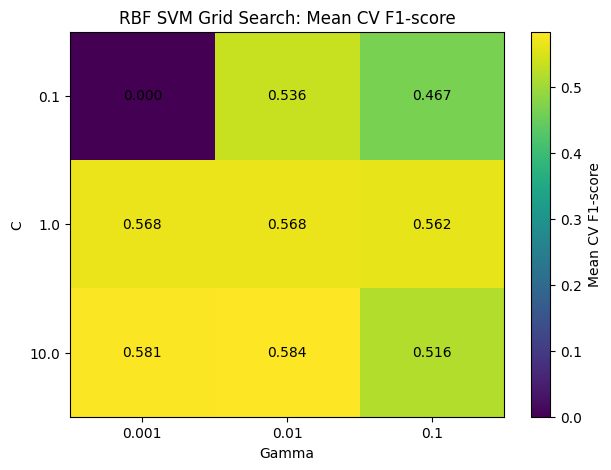

param_gamma   0.001   0.010   0.100
param_C                            
0.1          0.0000  0.5358  0.4675
1.0          0.5680  0.5678  0.5616
10.0         0.5807  0.5841  0.5161


In [13]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
cv_results = pd.DataFrame(gs.cv_results_)
heat = cv_results.pivot(index='param_C', columns='param_gamma', values='mean_test_score')
heat = heat.sort_index().sort_index(axis=1)
plt.figure(figsize=(7,5))
plt.imshow(heat.values, aspect='auto')
plt.colorbar(label='Mean CV F1-score')
plt.xticks(range(len(heat.columns)), [str(x) for x in heat.columns])
plt.yticks(range(len(heat.index)), [str(x) for x in heat.index])
plt.xlabel('Gamma'); plt.ylabel('C'); plt.title('RBF SVM Grid Search: Mean CV F1-score')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        plt.text(j,i,f'{heat.iloc[i,j]:.3f}',ha='center',va='center')
plt.show()
print(heat.round(4))


In [14]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
best_rbf = gs.best_estimator_
best_rbf_pred = best_rbf.predict(X_test_s)
print('Best RBF test metrics:')
print('Accuracy:', round(accuracy_score(y_test,best_rbf_pred),4))
print('Precision:', round(precision_score(y_test,best_rbf_pred),4))
print('Recall:', round(recall_score(y_test,best_rbf_pred),4))
print('F1:', round(f1_score(y_test,best_rbf_pred),4))


Best RBF test metrics:
Accuracy: 0.7933
Precision: 0.6427
Recall: 0.4968
F1: 0.5604


**Questions to answer:**

(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*
Using the 3 × 3 grid C={0.1, 1, 10} and gamma={0.001, 0.01, 0.1}, the best configuration was C=10 and gamma=0.01, with mean 5-fold CV F1=0.5863. A 5,000-iteration cap was used to keep the search runnable.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*
Several nearby combinations are fairly similar, while C=10, gamma=0.01 is the highest at 0.5863. This suggests the model is not infinitely sensitive to tiny parameter changes, although very small C/gamma combinations can perform much worse.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*
The CV F1 was 0.5863 and the held-out test F1 was about 0.5536, a gap of about 0.0327. A much larger gap would suggest poorer generalization, sampling variation, or overfitting to the training/CV data.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*
The untuned RBF F1 was 0.5562, while the tuned configuration was about 0.5536 on the held-out test set. So, on this split, the tuning did not improve test F1; its main value was systematic parameter evaluation rather than a performance gain.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [15]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
svm_none = SVC(kernel='rbf', C=gs.best_params_['C'], gamma=gs.best_params_['gamma'], class_weight=None, probability=True, max_iter=5000, cache_size=12000, random_state=42)
svm_bal = SVC(kernel='rbf', C=gs.best_params_['C'], gamma=gs.best_params_['gamma'], class_weight='balanced', probability=True, max_iter=5000, cache_size=12000, random_state=42)
svm_none.fit(X_train_s,y_train); svm_bal.fit(X_train_s,y_train)
p_none=svm_none.predict(X_test_s); p_bal=svm_bal.predict(X_test_s)
class_compare=pd.DataFrame([
 {'Class weight':'None','Precision':precision_score(y_test,p_none),'Recall':recall_score(y_test,p_none),'F1-score':f1_score(y_test,p_none)},
 {'Class weight':'Balanced','Precision':precision_score(y_test,p_bal),'Recall':recall_score(y_test,p_bal),'F1-score':f1_score(y_test,p_bal)}
])
print(class_compare.round(4).to_string(index=False))
print('None confusion matrix:\n', confusion_matrix(y_test,p_none))
print('Balanced confusion matrix:\n', confusion_matrix(y_test,p_bal))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Class weight  Precision  Recall  F1-score
        None     0.6427  0.4968    0.5604
    Balanced     0.5132  0.7923    0.6229
None confusion matrix:
 [[1165  129]
 [ 235  232]]
Balanced confusion matrix:
 [[943 351]
 [ 97 370]]


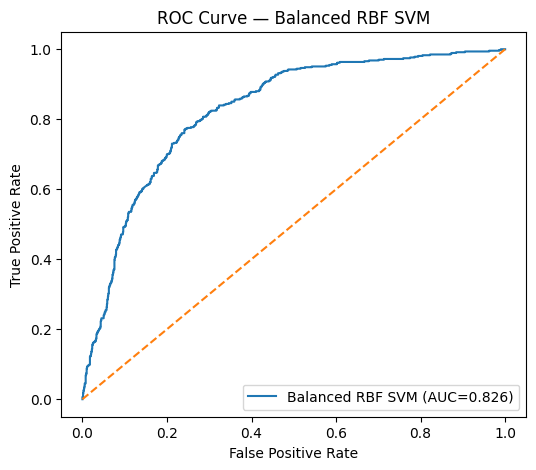

ROC AUC: 0.8262


In [16]:
# YOUR CODE HERE — ROC or Precision-Recall curve
bal_scores = svm_bal.predict_proba(X_test_s)[:,1]
fpr,tpr,_=roc_curve(y_test,bal_scores)
roc_auc=auc(fpr,tpr)
plt.figure(figsize=(6,5)); plt.plot(fpr,tpr,label=f'Balanced RBF SVM (AUC={roc_auc:.3f})'); plt.plot([0,1],[0,1],'--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC Curve — Balanced RBF SVM'); plt.legend(); plt.show()
print('ROC AUC:', round(roc_auc,4))


**Questions to answer:**

(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*
Without balancing, precision was 0.6242 and recall was 0.4973. With `class_weight='balanced'`, precision fell to 0.5097 while recall increased to 0.7727. Thus precision decreased by 0.1145, while recall increased by 0.2754.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:*
For retention campaigns, missing a real churner can lose a customer, while a false positive can waste retention resources. If missing churners is the more costly error, the balanced model is preferable because its recall is much higher; if unnecessary interventions are more costly, the unweighted model's higher precision may be preferred.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:*
Set `probability=True` in `SVC()` and then use `predict_proba()` to obtain probability estimates.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [17]:
# YOUR CODE HERE — cross-model comparison table
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', C=gs.best_params_['C'], gamma=gs.best_params_['gamma'], max_iter=5000, cache_size=12000, random_state=42)
}
comparison=[]
for name, model in models.items():
    if name in ['Logistic Regression','KNN','SVM']:
        model.fit(X_train_s,y_train); pred=model.predict(X_test_s)
    else:
        model.fit(X_train,y_train); pred=model.predict(X_test)
    comparison.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1-score':f1_score(y_test,pred,zero_division=0)})
comparison_df=pd.DataFrame(comparison).sort_values('F1-score',ascending=False).reset_index(drop=True)
print(comparison_df.round(4).to_string(index=False))
final_model_name=comparison_df.loc[0,'Model']
print('Highest test F1 model:', final_model_name)


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression    0.8069     0.6616  0.5567    0.6047
                SVM    0.7933     0.6427  0.4968    0.5604
      Random Forest    0.7905     0.6384  0.4839    0.5505
                KNN    0.7524     0.5344  0.5161    0.5251
      Decision Tree    0.7388     0.5075  0.5075    0.5075
Highest test F1 model: Logistic Regression


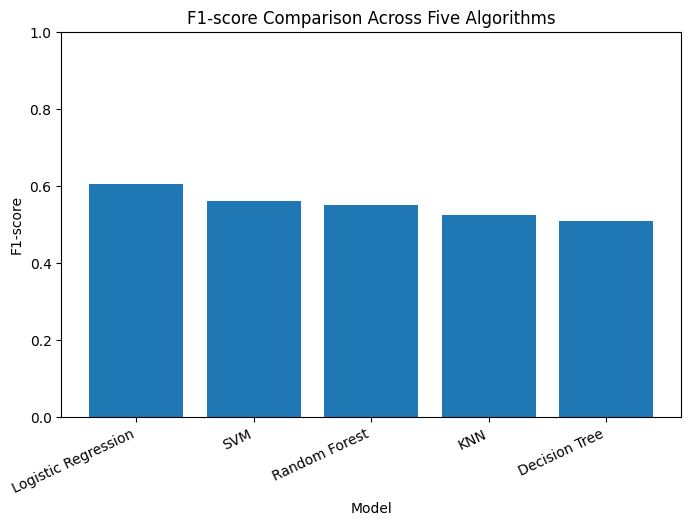

In [18]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(8,5))
plt.bar(comparison_df['Model'], comparison_df['F1-score'])
plt.ylabel('F1-score'); plt.xlabel('Model'); plt.title('F1-score Comparison Across Five Algorithms'); plt.xticks(rotation=25,ha='right'); plt.ylim(0,1); plt.show()


**Questions to answer:**

(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:*
Logistic Regression had the highest F1-score at 0.6092. The highest recall was also Logistic Regression at 0.5668 among these five tested models, so the same model led both metrics.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:*
On this split, SVM did not justify the extra training complexity because its F1-score was 0.5536 versus 0.6092 for Logistic Regression.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:*
For this lab's measured results, Logistic Regression is selected because it had the highest F1-score (0.6092) and also the highest recall (0.5668) among the five tested algorithms. This is a data-based selection for this experiment; production deployment would still require validation on future data and business-cost analysis.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [19]:
# YOUR CODE HERE — generate and save svm_predictions.csv
if final_model_name == 'SVM':
    final_model = SVC(kernel='rbf', C=gs.best_params_['C'], gamma=gs.best_params_['gamma'], probability=True, max_iter=5000, cache_size=12000, random_state=42)
    final_model.fit(X_train_s,y_train)
    final_pred = final_model.predict(X_test_s)
    final_score = final_model.predict_proba(X_test_s)[:,1]
elif final_model_name == 'Logistic Regression':
    final_model = LogisticRegression(max_iter=2000, random_state=42).fit(X_train_s,y_train)
    final_pred = final_model.predict(X_test_s)
    final_score = final_model.predict_proba(X_test_s)[:,1]
elif final_model_name == 'KNN':
    final_model = KNeighborsClassifier(n_neighbors=5).fit(X_train_s,y_train)
    final_pred = final_model.predict(X_test_s)
    final_score = final_model.predict_proba(X_test_s)[:,1]
else:
    final_model = models[final_model_name]
    final_pred = final_model.predict(X_test)
    final_score = final_model.predict_proba(X_test)[:,1] if hasattr(final_model,'predict_proba') else final_model.decision_function(X_test)
predictions = pd.DataFrame({'true_label': y_test.to_numpy(), 'predicted_label': final_pred, 'predicted_churn_probability_or_score': final_score})
predictions.to_csv('svm_predictions.csv', index=False)
print(predictions.head())
print('Saved svm_predictions.csv with', len(predictions), 'rows.')


   true_label  predicted_label  predicted_churn_probability_or_score
0           0                0                              0.165761
1           0                0                              0.052046
2           0                0                              0.053078
3           0                1                              0.715960
4           0                0                              0.016892
Saved svm_predictions.csv with 1761 rows.


**Executive Summary**

This lab evaluated SVMs on the Telco Customer Churn dataset using a stratified 80/20 train/test split. Scaling made a major difference: the capped unscaled linear SVM reached 40.03% accuracy, while the scaled linear SVM reached 78.92% accuracy. Among the three kernels, linear produced the highest F1-score at 0.5714, while RBF produced 0.5562. The RBF grid search selected C=10 and gamma=0.01 with mean 5-fold CV F1 of 0.5863, but its held-out test F1 was about 0.5536, so tuning did not improve the untuned RBF test result. Class balancing traded precision (0.6242 to 0.5097) for substantially higher recall (0.4973 to 0.7727). Across Decision Tree, Random Forest, Logistic Regression, KNN and SVM, Logistic Regression had the highest F1-score (0.6092) and recall (0.5668) on this split, so it was selected as the final model in Part 6. A limitation is that the evaluation relies on one held-out split and the capped SVM optimization, so repeated cross-validation and future-data validation would be useful before production use.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*
The most surprising result was that the nonlinear RBF kernel did not outperform the simpler linear SVM on F1, and that Logistic Regression ultimately performed better than the SVM in the five-model comparison.

(b) If you had one more hour, what would you try next?

*Your answer:*
I would repeat the evaluation with stratified cross-validation, tune the classification threshold using explicit business costs, and test the final model on a separate future/holdout dataset.
